# EcoCiudad IA · Módulo 1 — Predicción de la generación de residuos per cápita (regresión)

**Objetivo.** Estimar `gpc_kg_hab_dia` (kg de residuos por habitante y día) de un país a partir de variables socioeconómicas, y comparar varios modelos de regresión contra un *baseline*.
**Datos.** DS1, *What a Waste* (Banco Mundial), un país por fila: `data/processed/paises_residuos.csv` (Fase 2). Ver `docs/diccionario_datos.md`.

**Fuga de datos (obligatorio).** El objetivo es `residuos_total_ton_anio × 1000 ÷ 365 ÷ poblacion`. Por eso **no** se usa el total de residuos (ni nada derivado de él) como variable. Tampoco se usan la **composición** (consecuencia de lo que se genera; se reserva para el clustering) ni el **tratamiento** (resultado de la gestión y muy incompleto).

**Decisiones fijadas antes de ver resultados**
1. Partición: 20 % de prueba estratificado por `income_id` (semilla 42); validación cruzada repetida 5×3 sobre el 80 %. La prueba se usa **una sola vez**, para reportar.
2. Conjuntos de variables: **A0** (`gdp`, `poblacion`, `region_id`), **A** (A0 + `income_id`) y **B** (A + cobertura de recolección total de población, la columna de cobertura con menos vacíos).
3. Objetivo en escala lineal y en escala logarítmica (las métricas siempre se devuelven en kg/hab/día).
4. Conjunto para la app: el **más simple** cuyo mejor RMSE de validación cruzada no supere el mejor RMSE global más **una desviación estándar** entre pliegues (orden de simplicidad A0 < A < B). Motivo: la app debe pedir variables que una persona conozca y el simulador de PIB debe ser coherente (si `income_id` fuera variable, cambiar el PIB lo dejaría inconsistente).
5. Ajuste de hiperparámetros (`GridSearchCV`) solo para los 3 modelos más prometedores de ese conjunto; el ganador se elige por RMSE de validación cruzada, no por la prueba.
6. Métrica de selección: **RMSE** (los errores grandes son costosos: subestimar o sobreestimar mucho a un país distorsiona la planificación). Se reportan también **MAE** (robusto a atípicos), **MAPE** (error relativo; pesa más en países de baja generación) y **R²** (comparar con otros trabajos), además de Pearson *r*.
7. Los 5 países con mayor generación per cápita del conjunto (territorios pequeños de ingreso alto) se **conservan**; se reporta el desempeño con y sin ellos.
8. El baseline es el **promedio del grupo de ingreso**: un modelo que no lo supere no aporta, y se dirá con honestidad.

In [1]:
import json, sys, warnings, datetime
from pathlib import Path
import numpy as np, pandas as pd, joblib, sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_validate, GridSearchCV
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
try:
    import xgboost
    from xgboost import XGBRegressor
except ImportError:  # sin XGBoost el notebook sigue funcionando con los otros 6 modelos
    xgboost, XGBRegressor = None, None
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Raíz del proyecto (funciona ejecutando desde la raíz o desde notebooks/)
RAIZ = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "config.py").exists())
sys.path.insert(0, str(RAIZ))
import config
SEMILLA = config.RANDOM_STATE
N_JOBS = 1
FIG = config.DOCS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(exist_ok=True); config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
print("scikit-learn", sklearn.__version__, "| XGBoost:", xgboost.__version__ if xgboost else "no instalado (se omite)")

scikit-learn 1.9.1 | XGBoost: 3.4.1


## 1. Datos y partición

In [2]:
OBJ = "gpc_kg_hab_dia"
COB = "cobertura_total_percent_of_population"
df0 = pd.read_csv(config.DATA_PROCESSED / config.ARCHIVOS_PROCESADOS["paises"])
faltan = [c for c in ["iso3c", "pais", "income_id", "region_id", "gdp", "poblacion", COB, OBJ] if c not in df0.columns]
assert not faltan, f"Faltan columnas en el CSV: {faltan}"
df = df0.dropna(subset=[OBJ]).reset_index(drop=True)
assert (df[OBJ] > 0).all()
print(f"Países en el CSV: {len(df0)} | sin objetivo (se descartan): {len(df0) - len(df)} {df0.loc[df0[OBJ].isna(), 'pais'].tolist()} | usados: {len(df)}")
print("Vacíos % en las variables candidatas:", (df[["gdp", "poblacion", COB, "income_id", "region_id"]].isna().mean() * 100).round(1).to_dict())
print("Asimetría del objetivo: lineal =", round(df[OBJ].skew(), 2), "| logarítmico =", round(np.log(df[OBJ]).skew(), 2))

CONJUNTOS = {
    "A0": (["gdp", "poblacion"], ["region_id"]),
    "A": (["gdp", "poblacion"], ["income_id", "region_id"]),
    "B": (["gdp", "poblacion", COB], ["income_id", "region_id"]),
}
ORDEN_SIMPLICIDAD = ["A0", "A", "B"]
tr_idx, te_idx = train_test_split(df.index, test_size=0.2, random_state=SEMILLA, stratify=df["income_id"])
dtr, dte = df.loc[tr_idx].reset_index(drop=True), df.loc[te_idx].reset_index(drop=True)
ytr, yte = dtr[OBJ], dte[OBJ]
EXTREMOS = df.nlargest(5, OBJ)["iso3c"].tolist()
CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
print(f"Entrenamiento: {len(dtr)} | prueba: {len(dte)} | extremos (5 mayores gpc): {df.nlargest(5, OBJ)['pais'].tolist()}")
print("Países por grupo de ingreso (entrenamiento / prueba):", dtr["income_id"].value_counts().to_dict(), "/", dte["income_id"].value_counts().to_dict())

Países en el CSV: 217 | sin objetivo (se descartan): 2 ['Sint Maarten (Dutch part)', 'Turks and Caicos Islands'] | usados: 215
Vacíos % en las variables candidatas: {'gdp': 0.0, 'poblacion': 0.0, 'cobertura_total_percent_of_population': 57.2, 'income_id': 0.0, 'region_id': 0.0}
Asimetría del objetivo: lineal = 1.41 | logarítmico = -0.23


Entrenamiento: 172 | prueba: 43 | extremos (5 mayores gpc): ['Virgin Islands (U.S.)', 'Bermuda', 'Faeroe Islands', 'Monaco', 'Puerto Rico']
Países por grupo de ingreso (entrenamiento / prueba): {'HIC': 63, 'UMC': 45, 'LMC': 38, 'LIC': 26} / {'HIC': 16, 'UMC': 11, 'LMC': 9, 'LIC': 7}


## 2. Métricas y baseline (promedio por grupo de ingreso)

In [3]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(mean_squared_error(real, pred))), "MAE": float(mean_absolute_error(real, pred)),
            "MAPE": float(np.mean(np.abs((real - pred) / real)) * 100), "R2": float(r2_score(real, pred)),
            "Pearson_r": float(np.corrcoef(real, pred)[0, 1])}

class MediaPorGrupo(BaseEstimator, RegressorMixin):
    """Baseline: predice el promedio del grupo de ingreso (o el promedio global si el grupo no se vio)."""
    def fit(self, X, y):
        self.medias_ = pd.Series(np.asarray(y, float)).groupby(np.asarray(X["income_id"])).mean()
        self.global_ = float(np.mean(y))
        return self
    def predict(self, X):
        return pd.Series(np.asarray(X["income_id"])).map(self.medias_).fillna(self.global_).to_numpy()

SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
base_r = cross_validate(MediaPorGrupo(), dtr[["income_id"]], ytr, cv=CV, scoring=SCORING)
base_cv = {"RMSE_cv": float(-base_r["test_rmse"].mean()), "RMSE_cv_std": float(base_r["test_rmse"].std()),
           "MAE_cv": float(-base_r["test_mae"].mean()), "R2_cv": float(base_r["test_r2"].mean())}
baseline = MediaPorGrupo().fit(dtr[["income_id"]], ytr)
print("Baseline (promedio por grupo de ingreso) · validación cruzada:", {k: round(v, 3) for k, v in base_cv.items()})

Baseline (promedio por grupo de ingreso) · validación cruzada: {'RMSE_cv': 0.496, 'RMSE_cv_std': 0.105, 'MAE_cv': 0.336, 'R2_cv': 0.502}


## 3. Modelos
Preprocesamiento **dentro** del `Pipeline` (evita fuga de datos): logaritmo de las numéricas (`log1p`), imputación por mediana con indicador de faltante, escalado (salvo árboles) y one-hot para las categóricas. Modelos: Ridge (lineal), polinómica de grado 2 regularizada, SVR, KNN, Random Forest, MLP y XGBoost (si está instalado).

In [4]:
def prep(num, cat, escalar=True):
    num_pipe = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                         ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("esc", StandardScaler() if escalar else "passthrough")])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)])

def pasos(nombre, num, cat):
    if nombre == "Ridge (lineal)":
        return [("prep", prep(num, cat)), ("m", Ridge(alpha=1.0))]
    if nombre == "Polinómica g=2 (Ridge)":
        return [("prep", prep(num, cat)), ("poly", PolynomialFeatures(2)), ("m", Ridge(alpha=10.0))]
    if nombre == "SVR":
        return [("prep", prep(num, cat)), ("m", SVR(kernel="rbf", C=1.0))]
    if nombre == "KNN":
        return [("prep", prep(num, cat)), ("m", KNeighborsRegressor(n_neighbors=5))]
    if nombre == "Random Forest":
        return [("prep", prep(num, cat, False)), ("m", RandomForestRegressor(n_estimators=300, random_state=SEMILLA))]
    if nombre == "MLP":
        return [("prep", prep(num, cat)), ("m", MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=SEMILLA))]
    if nombre == "XGBoost":
        return [("prep", prep(num, cat, False)), ("m", XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                                   subsample=0.8, random_state=SEMILLA, n_jobs=1))]
    raise ValueError(nombre)

NOMBRES = ["Ridge (lineal)", "Polinómica g=2 (Ridge)", "SVR", "KNN", "Random Forest", "MLP"] + (["XGBoost"] if XGBRegressor else [])

def modelo(nombre, clave, log):
    num, cat = CONJUNTOS[clave]
    pipe = Pipeline(pasos(nombre, num, cat))
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp) if log else pipe
print("Modelos a comparar:", NOMBRES)

Modelos a comparar: ['Ridge (lineal)', 'Polinómica g=2 (Ridge)', 'SVR', 'KNN', 'Random Forest', 'MLP', 'XGBoost']


## 4. Ablación: modelos × conjuntos de variables × escala del objetivo (validación cruzada 5×3 sobre entrenamiento)

In [5]:
filas = []
for clave, (num, cat) in CONJUNTOS.items():
    Xtr = dtr[num + cat]
    for log in (False, True):
        for nombre in NOMBRES:
            r = cross_validate(modelo(nombre, clave, log), Xtr, ytr, cv=CV, scoring=SCORING, n_jobs=N_JOBS, error_score="raise")
            filas.append({"conjunto": clave, "objetivo": "log" if log else "lineal", "modelo": nombre,
                          "RMSE_cv": float(-r["test_rmse"].mean()), "RMSE_cv_std": float(r["test_rmse"].std()),
                          "MAE_cv": float(-r["test_mae"].mean()), "R2_cv": float(r["test_r2"].mean())})
res_cv = pd.DataFrame(filas)
res_cv.to_csv(config.DATA_PROCESSED / "m1_resultados_cv.csv", index=False)
tabla_cv = res_cv.groupby(["modelo", "conjunto"])["RMSE_cv"].min().unstack()[ORDEN_SIMPLICIDAD]
tabla_cv.loc["Baseline (promedio por ingreso)"] = base_cv["RMSE_cv"]
print("RMSE de validación cruzada (kg/hab/día; mejor escala del objetivo por celda):")
print(tabla_cv.round(3).to_string())

RMSE de validación cruzada (kg/hab/día; mejor escala del objetivo por celda):
conjunto                            A0      A      B
modelo                                              
KNN                              0.507  0.494  0.513
MLP                              0.468  0.467  0.489
Polinómica g=2 (Ridge)           0.469  0.459  0.475
Random Forest                    0.501  0.506  0.510
Ridge (lineal)                   0.472  0.459  0.466
SVR                              0.460  0.463  0.474
XGBoost                          0.525  0.528  0.525
Baseline (promedio por ingreso)  0.496  0.496  0.496


## 5. Selección del conjunto de la app (regla fijada de antemano) y ajuste de hiperparámetros

In [6]:
mejor_global = res_cv.loc[res_cv["RMSE_cv"].idxmin()]
umbral = mejor_global["RMSE_cv"] + mejor_global["RMSE_cv_std"]
mejor_por_conjunto = res_cv.groupby("conjunto")["RMSE_cv"].min()
elegido = next(c for c in ORDEN_SIMPLICIDAD if mejor_por_conjunto[c] <= umbral)
num, cat = CONJUNTOS[elegido]
print(f"Mejor global: conjunto {mejor_global['conjunto']}, {mejor_global['modelo']}, objetivo {mejor_global['objetivo']}, "
      f"RMSE_cv = {mejor_global['RMSE_cv']:.3f} ± {mejor_global['RMSE_cv_std']:.3f}")
print(f"Umbral (mejor + 1 desv. est.) = {umbral:.3f} | mejor RMSE_cv por conjunto: {mejor_por_conjunto.round(3).to_dict()}")
print(f"Conjunto elegido para la app: {elegido} -> variables {num + cat}")

top3 = res_cv[res_cv["conjunto"] == elegido].sort_values("RMSE_cv").drop_duplicates("modelo").head(3)
GRILLAS = {
    "Ridge (lineal)": {"m__alpha": [0.01, 0.1, 1, 10, 100]},
    "Polinómica g=2 (Ridge)": {"m__alpha": [1, 10, 100, 1000]},
    "SVR": {"m__C": [0.3, 1, 3, 10, 30], "m__epsilon": [0.01, 0.05, 0.1]},
    "KNN": {"m__n_neighbors": [3, 5, 8, 12, 20], "m__weights": ["uniform", "distance"]},
    "Random Forest": {"m__max_depth": [None, 3, 5, 8], "m__min_samples_leaf": [1, 3, 5]},
    "MLP": {"m__hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "m__alpha": [1e-4, 1e-2, 1e-1]},
    "XGBoost": {"m__max_depth": [2, 3, 4], "m__learning_rate": [0.03, 0.1], "m__n_estimators": [150, 300]},
}
Xtr, Xte = dtr[num + cat], dte[num + cat]
ajustados = []
for _, f in top3.iterrows():
    log = f["objetivo"] == "log"
    prefijo = "regressor__" if log else ""
    gs = GridSearchCV(modelo(f["modelo"], elegido, log), {prefijo + k: v for k, v in GRILLAS[f["modelo"]].items()},
                      cv=CV, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS, refit=True, error_score="raise")
    gs.fit(Xtr, ytr)
    ajustados.append({"modelo": f["modelo"], "objetivo": f["objetivo"], "RMSE_cv_sin_ajustar": float(f["RMSE_cv"]),
                      "RMSE_cv_ajustado": float(-gs.best_score_),
                      "RMSE_cv_std": float(gs.cv_results_["std_test_score"][gs.best_index_]),
                      "parametros": {k.replace("regressor__", "").replace("m__", ""): v for k, v in gs.best_params_.items()},
                      "estimador": gs.best_estimator_})
tabla_aj = pd.DataFrame([{k: v for k, v in a.items() if k != "estimador"} for a in ajustados])
print(tabla_aj.round(3).to_string())
ganador = min(ajustados, key=lambda a: a["RMSE_cv_ajustado"])
print(f"\nGanador por RMSE de validación cruzada: {ganador['modelo']} (objetivo {ganador['objetivo']}), "
      f"RMSE_cv = {ganador['RMSE_cv_ajustado']:.3f} ± {ganador['RMSE_cv_std']:.3f}; parámetros {ganador['parametros']}")
print("Nota: el RMSE_cv ajustado es algo optimista (se eligió el mejor de la rejilla); la prueba lo contrasta.")

Mejor global: conjunto A, Polinómica g=2 (Ridge), objetivo lineal, RMSE_cv = 0.459 ± 0.093
Umbral (mejor + 1 desv. est.) = 0.553 | mejor RMSE_cv por conjunto: {'A': 0.459, 'A0': 0.46, 'B': 0.466}
Conjunto elegido para la app: A0 -> variables ['gdp', 'poblacion', 'region_id']


                   modelo objetivo  RMSE_cv_sin_ajustar  RMSE_cv_ajustado  RMSE_cv_std                                       parametros
0                     SVR   lineal                0.460             0.460        0.094                         {'C': 1, 'epsilon': 0.1}
1                     MLP   lineal                0.468             0.467        0.086  {'alpha': 0.01, 'hidden_layer_sizes': (32, 16)}
2  Polinómica g=2 (Ridge)   lineal                0.469             0.469        0.088                                    {'alpha': 10}

Ganador por RMSE de validación cruzada: SVR (objetivo lineal), RMSE_cv = 0.460 ± 0.094; parámetros {'C': 1, 'epsilon': 0.1}
Nota: el RMSE_cv ajustado es algo optimista (se eligió el mejor de la rejilla); la prueba lo contrasta.


## 6. Evaluación en el conjunto de prueba (se usa una sola vez)

In [7]:
filas_t = [{"modelo": "Baseline: promedio por grupo de ingreso", **metricas(yte, baseline.predict(dte[["income_id"]]))}]
for a in ajustados:
    filas_t.append({"modelo": a["modelo"] + (" (ganador)" if a is ganador else ""), **metricas(yte, a["estimador"].predict(Xte))})
if (mejor_global["conjunto"] != elegido):
    m_g = modelo(mejor_global["modelo"], mejor_global["conjunto"], mejor_global["objetivo"] == "log")
    ng, cg = CONJUNTOS[mejor_global["conjunto"]]
    m_g.fit(dtr[ng + cg], ytr)
    filas_t.append({"modelo": f"Mejor global sin ajustar ({mejor_global['modelo']}, conjunto {mejor_global['conjunto']})",
                    **metricas(yte, m_g.predict(dte[ng + cg]))})
res_test = pd.DataFrame(filas_t)
res_test.to_csv(config.DATA_PROCESSED / "m1_resultados_test.csv", index=False)
print(f"Métricas en prueba (n = {len(dte)}; kg/hab/día salvo MAPE en % y R², r adimensionales):")
print(res_test.round(3).to_string(index=False))
met_ganador = metricas(yte, ganador["estimador"].predict(Xte))
met_base = metricas(yte, baseline.predict(dte[["income_id"]]))
print("\n¿El ganador supera al baseline en RMSE de prueba?", met_ganador["RMSE"] < met_base["RMSE"])

Métricas en prueba (n = 43; kg/hab/día salvo MAPE en % y R², r adimensionales):
                                                       modelo  RMSE   MAE   MAPE    R2  Pearson_r
                      Baseline: promedio por grupo de ingreso 0.501 0.319 43.789 0.398      0.661
                                                SVR (ganador) 0.443 0.268 36.729 0.529      0.736
                                                          MLP 0.477 0.297 36.076 0.454      0.704
                                       Polinómica g=2 (Ridge) 0.445 0.291 40.909 0.525      0.733
Mejor global sin ajustar (Polinómica g=2 (Ridge), conjunto A) 0.450 0.289 40.117 0.514      0.731

¿El ganador supera al baseline en RMSE de prueba? True


## 7. Robustez: con y sin los 5 países extremos

In [8]:
mask_te = ~dte["iso3c"].isin(EXTREMOS)
mask_tr = ~dtr["iso3c"].isin(EXTREMOS)
print(f"Extremos en entrenamiento: {int((~mask_tr).sum())} | en prueba: {int((~mask_te).sum())}")
sin_ext = {}
if mask_te.sum() > 5:
    sin_ext["baseline"] = metricas(yte[mask_te], baseline.predict(dte.loc[mask_te, ["income_id"]]))
    sin_ext["ganador_entrenado_con_todo"] = metricas(yte[mask_te], ganador["estimador"].predict(Xte[mask_te]))
    reent = clone(ganador["estimador"]).fit(Xtr[mask_tr], ytr[mask_tr])
    sin_ext["ganador_entrenado_sin_extremos"] = metricas(yte[mask_te], reent.predict(Xte[mask_te]))
    print(f"Prueba sin extremos (n = {int(mask_te.sum())}):")
    print(pd.DataFrame(sin_ext).T.round(3).to_string())
else:
    print("Muy pocos países de prueba sin extremos; no se calcula.")

Extremos en entrenamiento: 4 | en prueba: 1
Prueba sin extremos (n = 42):
                                 RMSE    MAE    MAPE     R2  Pearson_r
baseline                        0.442  0.288  43.682  0.333      0.679
ganador_entrenado_con_todo      0.420  0.250  36.871  0.397      0.689
ganador_entrenado_sin_extremos  0.401  0.241  36.580  0.449      0.705


## 8. Errores por grupo de ingreso, interpretabilidad y figuras

In [9]:
pred_te = ganador["estimador"].predict(Xte)
por_grupo = []
for g, idx in dte.groupby("income_id").groups.items():
    ii = list(idx)
    por_grupo.append({"grupo": g, "n": len(ii), "RMSE_ganador": float(np.sqrt(mean_squared_error(yte.iloc[ii], pred_te[ii]))),
                      "RMSE_baseline": float(np.sqrt(mean_squared_error(yte.iloc[ii], baseline.predict(dte.loc[ii, ["income_id"]])))),
                      "MAE_ganador": float(mean_absolute_error(yte.iloc[ii], pred_te[ii]))})
tabla_grupo = pd.DataFrame(por_grupo).sort_values("grupo")
print("Errores en prueba por grupo de ingreso (n pequeño: orientativo):")
print(tabla_grupo.round(3).to_string(index=False))

pi = permutation_importance(ganador["estimador"], Xte, yte, n_repeats=30, random_state=SEMILLA, scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"variable": num + cat, "aumento_RMSE": pi.importances_mean, "std": pi.importances_std}).sort_values("aumento_RMSE", ascending=False)
print("\nImportancia por permutación en prueba (aumento del RMSE al desordenar la variable):")
print(imp.round(3).to_string(index=False))

ridge = modelo("Ridge (lineal)", elegido, False).fit(Xtr, ytr)
coefs = pd.DataFrame({"variable": ridge.named_steps["prep"].get_feature_names_out(), "coeficiente": ridge.named_steps["m"].coef_})
coefs = coefs.reindex(coefs["coeficiente"].abs().sort_values(ascending=False).index)
print("\nCoeficientes del modelo lineal (numéricas estandarizadas; 10 mayores en valor absoluto):")
print(coefs.head(10).round(3).to_string(index=False))

Errores en prueba por grupo de ingreso (n pequeño: orientativo):
grupo  n  RMSE_ganador  RMSE_baseline  MAE_ganador
  HIC 16         0.459          0.582        0.323
  LIC  7         0.165          0.158        0.133
  LMC  9         0.700          0.724        0.391
  UMC 11         0.210          0.208        0.171



Importancia por permutación en prueba (aumento del RMSE al desordenar la variable):
 variable  aumento_RMSE   std
      gdp         0.277 0.051
poblacion         0.069 0.026
region_id         0.018 0.023

Coeficientes del modelo lineal (numéricas estandarizadas; 10 mayores en valor absoluto):
          variable  coeficiente
cat__region_id_NAC        0.675
          num__gdp        0.441
cat__region_id_EAS       -0.235
    num__poblacion       -0.180
cat__region_id_SAS       -0.159
cat__region_id_MEA       -0.102
cat__region_id_SSF       -0.077
cat__region_id_LCN       -0.063
cat__region_id_ECS       -0.040


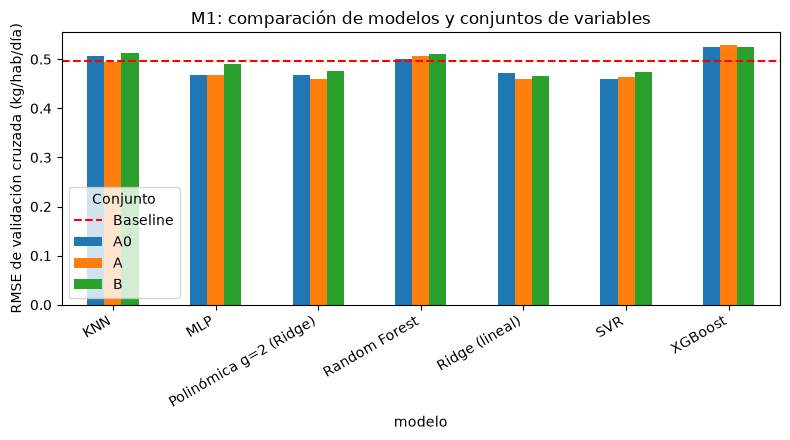

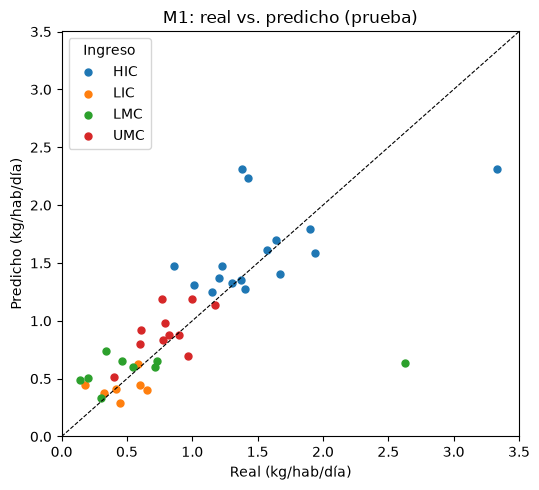

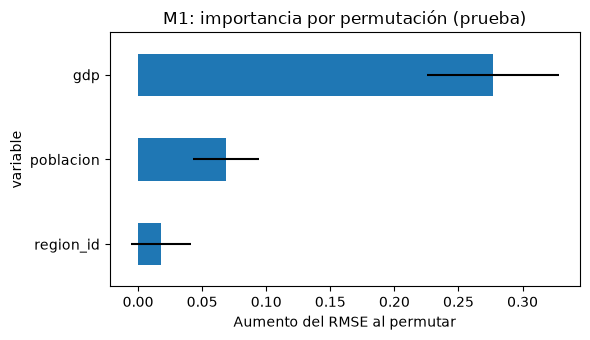

In [10]:
# Figuras para el informe
fig, ax = plt.subplots(figsize=(8, 4.5))
tabla_cv.drop(index="Baseline (promedio por ingreso)")[ORDEN_SIMPLICIDAD].plot.bar(ax=ax)
ax.axhline(base_cv["RMSE_cv"], color="red", ls="--", label="Baseline")
ax.set_ylabel("RMSE de validación cruzada (kg/hab/día)"); ax.set_title("M1: comparación de modelos y conjuntos de variables")
ax.legend(title="Conjunto"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(FIG / "m1_comparacion_cv.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
for g, sub in dte.assign(pred=pred_te).groupby("income_id"):
    ax.scatter(sub[OBJ], sub["pred"], label=g, s=25)
lim = [0, max(dte[OBJ].max(), pred_te.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Real (kg/hab/día)"); ax.set_ylabel("Predicho (kg/hab/día)"); ax.set_title("M1: real vs. predicho (prueba)")
ax.legend(title="Ingreso"); plt.tight_layout(); plt.savefig(FIG / "m1_real_vs_predicho.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
imp.iloc[::-1].plot.barh(x="variable", y="aumento_RMSE", xerr="std", ax=ax, legend=False)
ax.set_xlabel("Aumento del RMSE al permutar"); ax.set_title("M1: importancia por permutación (prueba)")
plt.tight_layout(); plt.savefig(FIG / "m1_importancia.png", dpi=130); plt.show()

## 9. Reentrenar con todos los países y guardar el modelo
Las métricas de arriba salen del modelo entrenado solo con el 80 %. Para la app se reentrena el ganador con **todos** los países con objetivo (después de reportar las métricas).

In [11]:
def a_json(x):
    if isinstance(x, dict): return {str(k): a_json(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [a_json(v) for v in x]
    if isinstance(x, (np.floating, float)): return None if np.isnan(x) else float(x)
    if isinstance(x, (np.integer,)): return int(x)
    return x

final = clone(ganador["estimador"]).fit(df[num + cat], df[OBJ])
joblib.dump(final, config.MODELS_DIR / "prediccion_mejor.pkl")
recarga = joblib.load(config.MODELS_DIR / "prediccion_mejor.pkl")
assert np.allclose(recarga.predict(df[num + cat].head(5)), final.predict(df[num + cat].head(5)))

def ref(col):
    g = df.groupby(col)[OBJ]
    return {k: {"media": float(g.mean()[k]), "mediana": float(g.median()[k]), "n": int(g.size()[k])} for k in g.size().index}

librerias = {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__}
if ganador["modelo"] == "XGBoost": librerias["xgboost"] = xgboost.__version__
meta = {
    "modulo": "prediccion",
    "modelo": f"{ganador['modelo']} (objetivo {ganador['objetivo']}, conjunto {elegido})",
    "fecha": datetime.date.today().isoformat(),
    "dataset": "DS1 What a Waste (nivel país), data/processed/paises_residuos.csv; objetivo gpc_kg_hab_dia derivado",
    "n_entrenamiento": int(len(dtr)), "n_prueba": int(len(dte)),
    "parametros": ganador["parametros"],
    "metricas": {"RMSE": met_ganador["RMSE"], "MAE": met_ganador["MAE"], "MAPE": met_ganador["MAPE"], "R2": met_ganador["R2"],
                 "Pearson_r": met_ganador["Pearson_r"]},
    "features": num + cat, "clases": [], "librerias": librerias,
    "conjunto_variables": elegido, "objetivo_log": ganador["objetivo"] == "log",
    "metricas_cv": {"RMSE_cv": ganador["RMSE_cv_ajustado"], "RMSE_cv_std": ganador["RMSE_cv_std"]},
    "baseline": {"descripcion": "promedio del grupo de ingreso", "metricas_prueba": met_base, "cv": base_cv},
    "metricas_sin_extremos": sin_ext, "extremos": EXTREMOS,
    "importancia_permutacion": imp.set_index("variable")["aumento_RMSE"].to_dict(),
    "referencias_app": {"por_ingreso": ref("income_id"), "por_region": ref("region_id")},
    "rangos_variables": {c: {"min": float(df[c].min()), "p05": float(df[c].quantile(0.05)), "mediana": float(df[c].median()),
                             "p95": float(df[c].quantile(0.95)), "max": float(df[c].max())} for c in num},
    "categorias": {c: sorted(df[c].dropna().unique().tolist()) for c in cat},
    "gdp_por_ingreso": {g: [float(s["gdp"].min()), float(s["gdp"].max())] for g, s in df.groupby("income_id")},
    "notas": ("Estima un promedio nacional (no una ciudad); los años de referencia difieren entre países; "
              "relación socioeconómica no causal; muestra pequeña, por lo que las métricas tienen incertidumbre; "
              "los territorios pequeños de ingreso alto son extremos. El grupo de ingreso se deriva del ingreso nacional, "
              "así que está muy relacionado con el PIB."),
}
(config.MODELS_DIR / "prediccion_meta.json").write_text(json.dumps(a_json(meta), ensure_ascii=False, indent=2), encoding="utf-8")
print("Guardados: models/prediccion_mejor.pkl y models/prediccion_meta.json | features:", num + cat)

Guardados: models/prediccion_mejor.pkl y models/prediccion_meta.json | features: ['gdp', 'poblacion', 'region_id']


## 10. Resumen para el informe (se guarda en `data/processed/m1_resumen.txt`)

In [12]:
L = [f"Países usados: {len(df)} (entrenamiento {len(dtr)}, prueba {len(dte)}); descartados sin objetivo: {len(df0) - len(df)}",
     f"scikit-learn {sklearn.__version__}; XGBoost: {xgboost.__version__ if xgboost else 'no instalado'}",
     "", "RMSE de validación cruzada (kg/hab/día):", tabla_cv.round(3).to_string(),
     "", f"Mejor global: conjunto {mejor_global['conjunto']}, {mejor_global['modelo']}, objetivo {mejor_global['objetivo']}, "
         f"RMSE_cv = {mejor_global['RMSE_cv']:.3f} ± {mejor_global['RMSE_cv_std']:.3f}; umbral = {umbral:.3f}",
     f"Mejor RMSE_cv por conjunto: {mejor_por_conjunto.round(3).to_dict()}",
     f"Conjunto elegido para la app: {elegido} -> {num + cat}",
     "", "Modelos ajustados (top 3):", tabla_aj.round(3).to_string(),
     f"Ganador: {ganador['modelo']} (objetivo {ganador['objetivo']}), parámetros {ganador['parametros']}",
     "", f"Métricas en prueba (n = {len(dte)}):", res_test.round(3).to_string(index=False),
     "", f"Prueba sin extremos {EXTREMOS}:", pd.DataFrame(sin_ext).T.round(3).to_string() if sin_ext else "no calculada",
     "", "Por grupo de ingreso (prueba):", tabla_grupo.round(3).to_string(index=False),
     "", "Importancia por permutación:", imp.round(3).to_string(index=False),
     "", "Coeficientes del modelo lineal (10 mayores):", coefs.head(10).round(3).to_string(index=False)]
texto = "\n".join(L)
(config.DATA_PROCESSED / "m1_resumen.txt").write_text(texto + "\n", encoding="utf-8")
print(texto)

Países usados: 215 (entrenamiento 172, prueba 43); descartados sin objetivo: 2
scikit-learn 1.9.1; XGBoost: 3.4.1

RMSE de validación cruzada (kg/hab/día):
conjunto                            A0      A      B
modelo                                              
KNN                              0.507  0.494  0.513
MLP                              0.468  0.467  0.489
Polinómica g=2 (Ridge)           0.469  0.459  0.475
Random Forest                    0.501  0.506  0.510
Ridge (lineal)                   0.472  0.459  0.466
SVR                              0.460  0.463  0.474
XGBoost                          0.525  0.528  0.525
Baseline (promedio por ingreso)  0.496  0.496  0.496

Mejor global: conjunto A, Polinómica g=2 (Ridge), objetivo lineal, RMSE_cv = 0.459 ± 0.093; umbral = 0.553
Mejor RMSE_cv por conjunto: {'A': 0.459, 'A0': 0.46, 'B': 0.466}
Conjunto elegido para la app: A0 -> ['gdp', 'poblacion', 'region_id']

Modelos ajustados (top 3):
                   modelo objetivo  RMSE_cv